<center><h1> IFT-6758  Science des Données  </h1></center>
<center><h2> Automne 2022 </h2></center> 
<center><h3> Labo - 4</h3></center> 
<center><h3> </h3></center> 
<center><h3> scikit-learn</h3></center> 



### Installation
Sur Google colab `sklearn` est déjà installé.

In [73]:
!pip install sklearn
!pip install seaborn==0.11

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
  Created wheel for sklearn: filename=sklearn-0.0-py2.py3-none-any.whl size=1310 sha256=cac845b88a6fa2c0c344becdc1e326c358160a7e87f4cd642ee1e7535c4df3ea
  Stored in directory: /root/.cache/pip/wheels/46/ef/c3/157e41f5ee1372d1be90b09f74f82b10e391eaacca8f22d33e
Successfully built sklearn
Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     |████████████████████████████████| 283 kB 5.2 MB/s 
  Attempting uninstall: seaborn
    Found existing installation: seaborn 0.11.2
    Uninstalling seaborn-0.11.2:
      Successfully uninstalled seaborn-0.11.2


### Import

In [28]:
import sklearn

# [1]. Introduction

Scikit-learn est une bibliothèque d'apprentissage automatique open source qui supporte l'apprentissage supervisé et non supervisé. Scikit-Learn se caractérise par un API propre, uniforme et facile à utiliser. Il fournit également divers outils pour l'ajustement des modèles, le prétraitement des données, la sélection et l'évaluation des modèles, ainsi que de nombreux autres algorithmes et modèles d'apprentissage automatique intégrés.

### Outils dans Scikit-Learn
* Prétraitement des données
* Sélection/extraction de charactéristiques
* Réduction de dimensionnalité
* Classification
* Régression
* Regroupement
* Estimation de la densité
* Sélection de modèle


Le plus souvent, les étapes d'utilisation des API Scikit-Learn sont les suivantes :

* Pré-traiter les données.
* Choisissez une classe de modèle en important la classe d'estimateur appropriée depuis Scikit-Learn.
* Choisissez les hyperparamètres du modèle en instanciant cette classe avec les valeurs souhaitées.
* Organisez les données dans une matrice de caractéristiques et un vecteur cible en suivant la discussion ci-dessus.
* Ajustez le modèle à vos données en appelant la méthode `fit()` de l'instance de modèle.
* Appliquez le modèle à de nouvelles données :
    * Pour l'apprentissage supervisé, nous prédisons souvent des étiquettes pour des données inconnues
 en utilisant la méthode `predict()`.
    * Pour l'apprentissage non supervisé, nous transformons ou déduisons souvent des propriétés des données à l'aide de la méthode `transform()` ou `predict()`.

## Téléchargez le dataset Iris

In [49]:
from sklearn import datasets

# load iris dataset
iris = datasets.load_iris()
X_iris = iris.data
y_iris = iris.target

iris.feature_names, iris.target_names

(['sepal length (cm)',
  'sepal width (cm)',
  'petal length (cm)',
  'petal width (cm)'],
 array(['setosa', 'versicolor', 'virginica'], dtype='<U10'))

In [50]:
X_iris.shape, y_iris.shape

((150, 4), (150,))

In [53]:
X_iris[0:3], y_iris[0:3]

(array([[5.1, 3.5, 1.4, 0.2],
        [4.9, 3. , 1.4, 0.2],
        [4.7, 3.2, 1.3, 0.2]]), array([0, 0, 0]))

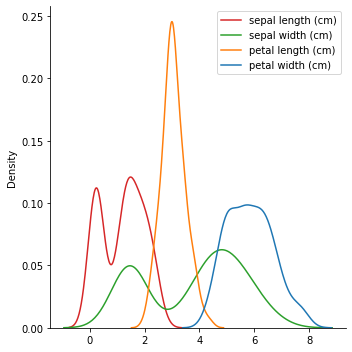

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.displot(data=X_iris, kind='kde', legend=False);
plt.legend(iris.feature_names);


#[2] Prétraitement

## Codage de charactéristiques

1. Entrée: [OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html) and [OrdinalEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OrdinalEncoder.html)
2. Étiquette: [LabelBinarizer](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.LabelBinarizer.html) and [LabelEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.LabelEncoder.html)



In [56]:
from sklearn.preprocessing import OrdinalEncoder
enc = OrdinalEncoder()
X = [['male', 'from US', 'uses Safari'], ['female', 'from Europe', 'uses Firefox'], ['female', 'from Asia', 'uses Chrome']]
enc.fit(X)

print(enc.transform([['female', 'from US', 'uses Safari']]))
print(enc.transform([['male', 'from Europe', 'uses Firefox']]))

test = enc.transform([['male', 'from Asia', 'uses Chrome']])
print(test)
enc.inverse_transform(test)

[[0. 2. 2.]]
[[1. 1. 1.]]
[[1. 0. 0.]]


array([['male', 'from Asia', 'uses Chrome']], dtype=object)

In [62]:
from sklearn.preprocessing import OneHotEncoder
enc = OneHotEncoder()
X = [['male', 'from US', 'uses Safari'], ['female', 'from Europe', 'uses Firefox'], ['female', 'from Asia', 'uses Chrome']]
enc.fit(X)
print(enc.transform([['female', 'from US', 'uses Safari'],
               ['male', 'from Europe', 'uses Safari']]).toarray())
enc.get_feature_names_out(["gender", "origin", "browser"])

[[1. 0. 0. 0. 1. 0. 0. 1.]
 [0. 1. 0. 1. 0. 0. 0. 1.]]


array(['gender_female', 'gender_male', 'origin_from Asia',
       'origin_from Europe', 'origin_from US', 'browser_uses Chrome',
       'browser_uses Firefox', 'browser_uses Safari'], dtype=object)

In [64]:
from sklearn.preprocessing import LabelBinarizer
lb = LabelBinarizer()
print(lb.fit_transform(['yes', "maybe", 'no', 'no', 'yes']))
print(lb.classes_)

[[0 0 1]
 [1 0 0]
 [0 1 0]
 [0 1 0]
 [0 0 1]]
['maybe' 'no' 'yes']


In [65]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
le.fit(["paris", "paris", "tokyo", "amsterdam"])

print(le.classes_)
print(le.transform(["tokyo", "tokyo", "paris", "amsterdam"]))
list(le.inverse_transform([2, 2, 1, 0]))

['amsterdam' 'paris' 'tokyo']
[2 2 1 0]


['tokyo', 'tokyo', 'paris', 'amsterdam']

## Normalization


In [70]:
from sklearn.preprocessing import minmax_scale
X_iris_scaled = minmax_scale(X_iris, feature_range=(0, 1))

X_iris_scaled[0:3]
# X_iris

array([[0.22222222, 0.625     , 0.06779661, 0.04166667],
       [0.16666667, 0.41666667, 0.06779661, 0.04166667],
       [0.11111111, 0.5       , 0.05084746, 0.04166667]])

In [71]:
X = X_iris
X_std = (X - X.min(axis=0)) / (X.max(axis=0) - X.min(axis=0))
X_scaled = X_std * (1 - 0) + 0

X_scaled[0:3]

array([[0.22222222, 0.625     , 0.06779661, 0.04166667],
       [0.16666667, 0.41666667, 0.06779661, 0.04166667],
       [0.11111111, 0.5       , 0.05084746, 0.04166667]])

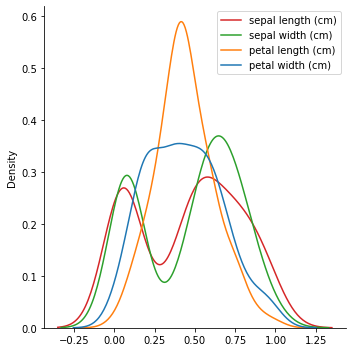

In [76]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.displot(data=X_iris_scaled, kind='kde', legend=False);
plt.legend(iris.feature_names);

## Sélection de Charactéristiques




In [78]:
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import chi2

selector = SelectKBest(chi2, k=2)
X_selected_feat_iris = selector.fit_transform(X_iris_scaled, y_iris)
print(X_selected_feat_iris.shape)
print(selector.get_support())

(150, 2)
[False False  True  True]


In [ ]:
chi2_values = chi2(X_iris_scaled, y_iris)
chi2_values

(array([11.37727382,  4.4707335 , 26.86193631, 30.47806752]),
 array([3.38420280e-03, 1.06952898e-01, 1.46894199e-06, 2.40863909e-07]))

In [ ]:
import pandas as pd
df = pd.DataFrame(X_iris, columns=iris.feature_names)
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2



# [3] Pipeline Sklearn


### Séparation Entrainement et Test

In [32]:
from sklearn.model_selection import train_test_split

# split dataset to train and test
X_train, X_test, y_train, y_test = train_test_split(X_selected_feat_iris, y_iris, 
                                                    test_size=0.2, 
                                                    shuffle=True, 
                                                    random_state=76 #  To guarantee that the split will always be the same
                                                    )  


In [79]:
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((120, 2), (120,), (30, 2), (30,))

### Aligner un classifieur

In [87]:
from sklearn.linear_model import LogisticRegression
classifier = LogisticRegression(C=1)

classifier.fit(X_train, y_train)

LogisticRegression(C=1)

### Score and Confusion Matrix

In [88]:
classifier.score(X_test, y_test)

0.9666666666666667

In [89]:
y_pred = classifier.predict(X_test)
y_pred

array([0, 1, 0, 2, 2, 1, 0, 1, 1, 2, 0, 2, 1, 1, 0, 0, 0, 2, 1, 0, 2, 0,
       0, 0, 0, 0, 2, 1, 0, 1])

In [91]:
from sklearn import metrics
metrics.accuracy_score(y_test, y_pred)

0.9666666666666667

In [92]:
metrics.confusion_matrix(y_test, y_pred)

array([[14,  0,  0],
       [ 0,  9,  1],
       [ 0,  0,  6]])

/usr/local/lib/python3.7/dist-packages/sklearn/utils/deprecation.py:87: FutureWarning: Function plot_confusion_matrix is deprecated; Function `plot_confusion_matrix` is deprecated in 1.0 and will be removed in 1.2. Use one of the class methods: ConfusionMatrixDisplay.from_predictions or ConfusionMatrixDisplay.from_estimator.
  warnings.warn(msg, category=FutureWarning)


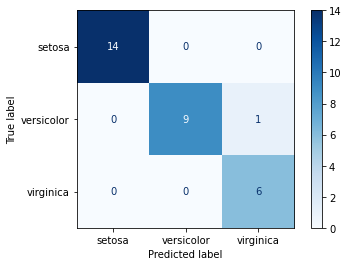

In [93]:
from sklearn.metrics import plot_confusion_matrix
disp = plot_confusion_matrix(classifier, X_test, y_test,
                                 display_labels=iris.target_names,
                                 cmap=plt.cm.Blues)

# [4] Prédiction de Prix de Maison - Régression


In [94]:
from sklearn import datasets

# load iris dataset
d_housing = datasets.fetch_california_housing()
X = d_housing.data  
y = d_housing.target

d_housing.feature_names

['MedInc',
 'HouseAge',
 'AveRooms',
 'AveBedrms',
 'Population',
 'AveOccup',
 'Latitude',
 'Longitude']

In [95]:
X.shape, y.shape

((20640, 8), (20640,))

In [96]:
import pandas as pd
df_housing = pd.DataFrame(X, columns=d_housing.feature_names)

In [97]:
df_housing.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [98]:
df_housing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
dtypes: float64(8)
memory usage: 1.3 MB


In [ ]:
df_housing.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000


In [99]:
y

array([4.526, 3.585, 3.521, ..., 0.923, 0.847, 0.894])

### Régression Linéaire

In [100]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(df_housing, y, 
                                                    test_size=0.3, 
                                                    shuffle=True, 
                                                    random_state=76)  

from sklearn.linear_model import LinearRegression
regressor = LinearRegression()
regressor.fit(X_train, y_train)
regressor.score(X_test, y_test)

0.598727562729147

In [101]:
metrics.mean_squared_error(y_test, regressor.predict(X_test))

0.5297475992493264

In [102]:
regressor.predict(X_test[0:10])

array([1.25318167, 2.34407458, 2.58640119, 1.78405408, 1.27349142,
       3.07178571, 0.96065724, 2.78040214, 0.70305497, 0.87464286])

In [ ]:
y_test[0:10]

array([0.774, 1.992, 2.168, 1.505, 1.625, 4.029, 1.463, 3.821, 1.383,
       1.146])

Utiliser la mise à l'échelle et la sélection de charactéristiques pour la régression

In [104]:
from sklearn.preprocessing import minmax_scale
df_housing_scaled = minmax_scale(df_housing)

from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import f_regression
X_selected_feat_housing = SelectKBest(f_regression, k=6).fit_transform(df_housing, y)

X_train, X_test, y_train, y_test = train_test_split(X_selected_feat_housing, y, 
                                                    test_size=0.3, 
                                                    shuffle=True, 
                                                    random_state=76)
  
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

from sklearn.linear_model import LinearRegression
regressor = LinearRegression()
regressor.fit(X_train, y_train)
y_pred = regressor.predict(X_test)
regressor.score(X_test, y_test)

(14448, 6) (6192, 6) (14448,) (6192,)


0.5979063765808008

In [105]:
## RMSE Metric
from sklearn.metrics import mean_squared_error
import math
rmse = math.sqrt(mean_squared_error(y_test, y_pred))
print(f"RMSE -> {rmse}")

RMSE -> 0.728581981720232


### Fetching Weights and Bias from the model

In [106]:
bias = regressor.intercept_
weights = regressor.coef_ 

print(f"Weights -> {weights}")
print(f"Bias -> {bias}")

Weights -> [ 0.43987179  0.00969571 -0.10598027  0.63178084 -0.42445209 -0.4404535 ]
Bias -> -37.56285762938924


In [ ]:
sum(X_test[0]*weights) + bias

1.248467066591978

In [ ]:
regressor.predict([X_test[0]])

array([1.24846707])

# [5] Arbres de Décisions 

<a href="https://towardsdatascience.com/understanding-random-forest-58381e0602d2" rel="DT">![](https://miro.medium.com/max/1000/1*LMoJmXCsQlciGTEyoSN39g.jpeg)</a>

Forêt d'arbres décisionnels

<a href="https://towardsdatascience.com/understanding-random-forest-58381e0602d2" rel="DT">![](https://miro.medium.com/max/1000/1*VHDtVaDPNepRglIAv72BFg.jpeg)</a>

https://scikit-learn.org/stable/modules/tree.html

In [108]:
## House Price - Regression
X_train, X_test, y_train, y_test = train_test_split(X_selected_feat_housing, y, 
                                                    test_size=0.3, 
                                                    shuffle=True, 
                                                    random_state=76 #  To guarantee that the split will always be the same
                                                    ) 

# Decision Trees
from sklearn.tree import DecisionTreeRegressor
regressor = DecisionTreeRegressor()
regressor.fit(X_train, y_train)
y_pred = regressor.predict(X_test)
rmse = math.sqrt(mean_squared_error(y_test, y_pred))
print(f"Decision Tree: RMSE -> {rmse}")

# Random Forest
from sklearn.ensemble import RandomForestRegressor
regressor = RandomForestRegressor()
regressor.fit(X_train, y_train)
y_pred = regressor.predict(X_test)
rmse = math.sqrt(mean_squared_error(y_test, y_pred))
print(f"Random Forest: RMSE -> {rmse}")

Decision Tree: RMSE -> 0.7167687529875775
Random Forest: RMSE -> 0.507062730730758


In [109]:
## Iris - Classification
X_train, X_test, y_train, y_test = train_test_split(X_selected_feat_iris, y_iris, 
                                                    test_size=0.3, 
                                                    shuffle=True, 
                                                    random_state=76 #  To guarantee that the split will always be the same
                                                    ) 

# Decision Tree
from sklearn.tree import DecisionTreeClassifier
classifier = DecisionTreeClassifier()
classifier.fit(X_train, y_train)
score = classifier.score(X_test, y_test)
print(f"Decision Tree: Accuracy Score -> {score}")

# Random Forest
from sklearn.ensemble import RandomForestClassifier
classifier = RandomForestClassifier()
classifier.fit(X_train, y_train)
score = classifier.score(X_test, y_test)
print(f"Random Forest: Accuracy Score -> {score}")

Decision Tree: Accuracy Score -> 0.9555555555555556
Random Forest: Accuracy Score -> 0.9777777777777777


In [ ]:
import graphviz

# [6] Validation Croisée

<a href="https://scikit-learn.org/stable/modules/cross_validation.html" rel="K fold Cross Val">![](https://scikit-learn.org/stable/_images/grid_search_cross_validation.png)</a>



In [110]:
from sklearn.model_selection import cross_val_score
scores = cross_val_score(classifier, X_train, y_train, cv=5)
print(f"Scores ==> {scores}")
print("Mean Accuracy: %0.2f (+/- %0.2f)" % (scores.mean(), scores.std() * 2))

Scores ==> [0.95238095 1.         0.9047619  0.9047619  0.95238095]
Mean Accuracy: 0.94 (+/- 0.07)


# EXERCICES

### Données Text

1. Téléchargez n'importe quel ensemble de données textuelles de Sklearn pour la tâche de classification. (*par exemple fetch_20newsgroups*)
2. Prétraitez (*supprimez les mots vides, les caractères spéciaux, les espaces, etc.*) des données.
3. Extrayez les entités du jeu de données texte à l'aide de CountVectorizer ou TfidfVectorizer.
(*car le modèle a besoin de nombres et ces caractéristiques deviendront les colonnes X_train*)
4. Convertissez les Ylabels en nombres (s'ils sont en texte) à l'aide de LabelEncoder.
5. Entraînez le classificateur Naive Bayes et comparez les résultats avec un autre classificateur de votre choix. (*tel que SVM, Decision Tree, AdaBoost*)
6. Tracez une matrice de confusion pour analyser vos résultats.

Exercices bonis

https://github.com/mpfrush/Python-Scikit-Learn-Exercises/

# RÉFÉRENCES

1.  https://scikit-learn.org/stable/tutorial/index.html
2.  https://scikit-learn.org/stable/user_guide.html
3.  https://elitedatascience.com/python-machine-learning-tutorial-scikit-learn  


## Cheatsheet:
1. https://s3.amazonaws.com/assets.datacamp.com/blog_assets/Scikit_Learn_Cheat_Sheet_Python.pdf
2. https://scikit-learn.org/stable/tutorial/machine_learning_map/index.html